# Praktikum 3 - Penerapan Artificial Neural Network untuk Masalah Regresi

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Bagian 1: Regresi Sederhana Prediksi Harga Rumah (Data Dummy) & Tugas 4

Pada bagian pertama ini, model JST digunakan untuk memprediksi harga rumah berdasarkan luas tanah menggunakan data dummy.
Fitur dan target distandarisasi terlebih dahulu menggunakan `StandardScaler`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Pastikan seed tetap
tf.random.set_seed(42)
np.random.seed(42)

# Contoh dataset dummy luas vs harga
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})
X = data[['luas']]
y = data[['harga']]

# Normalisasi fitur dan target
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)
print(f"X_train:\n{X_train}\ny_train:\n{y_train}")

# Model Regresi Sederhana
model_dummy = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)  # Output layer linear untuk regresi kontinu
])
model_dummy.compile(optimizer='adam', loss='mse')
h_dummy = model_dummy.fit(X_train, y_train, epochs=100, verbose=0)

# Evaluasi prediksi
y_pred_scaled = model_dummy.predict(X_test, verbose=0)
y_pred_asli = scaler_y.inverse_transform(y_pred_scaled)
y_test_asli = scaler_y.inverse_transform(y_test)

print(f"Prediksi Nilai Ternormalisasi : {y_pred_scaled.ravel()}")
print(f"Prediksi Harga Sebenarnya     : {y_pred_asli.ravel()}")
print(f"Target Harga Aktual           : {y_test_asli.ravel()}")

X_train:
[[ 1.41421356]
 [ 0.        ]
 [-1.41421356]
 [ 0.70710678]]
y_train:
[[ 1.41421356]
 [ 0.        ]
 [-1.41421356]
 [ 0.70710678]]
Prediksi Nilai Ternormalisasi : [-0.30283505]
Prediksi Harga Sebenarnya     : [657.17267]
Target Harga Aktual           : [600.]


### Tugas 4: Eksperimen Variasi Nilai Learning Rate pada Regresi Dummy

Kita menguji performa konvergensi fungsi loss MSE dengan memvariasikan laju pembelajaran (*learning rate*)
pada optimizer Adam: $\eta \in [0.001, 0.01, 0.1, 0.5]$.

Pengaruh Variasi Learning Rate terhadap Konvergensi Regresi:
 Learning Rate  MSE Loss Awal  MSE Loss Akhir  Prediksi Harga  Target Aktual  Selisih Error
         0.001       1.597674        0.421495      656.983582          600.0      56.983582
         0.010       0.994561        0.001784      578.297485          600.0      21.702515
         0.100       0.900089        0.000002      592.057556          600.0       7.942444
         0.500       1.858225        0.000006      582.655579          600.0      17.344421


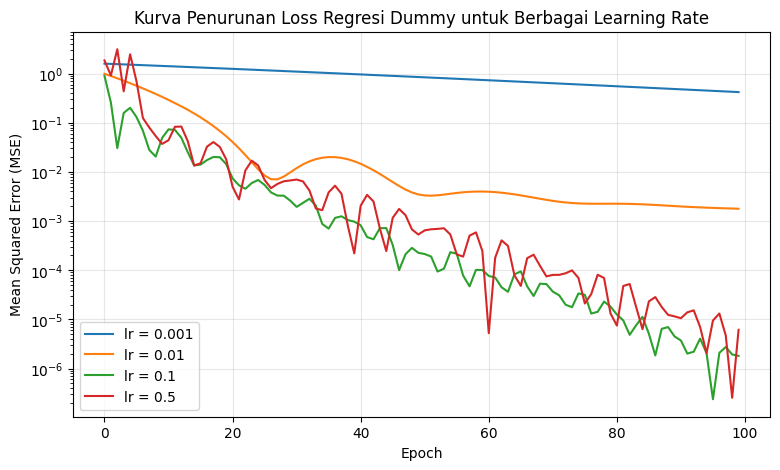

In [2]:
learning_rates = [0.001, 0.01, 0.1, 0.5]
lr_histories = {}
lr_results = []

for lr in learning_rates:
    tf.random.set_seed(42)
    np.random.seed(42)
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    opt = tf.keras.optimizers.Adam(learning_rate=lr)
    m.compile(optimizer=opt, loss='mse')
    h = m.fit(X_train, y_train, epochs=100, verbose=0)
    loss_akhir = h.history['loss'][-1]
    pred_s = m.predict(X_test, verbose=0)
    pred_act = scaler_y.inverse_transform(pred_s)[0, 0]
    actual = scaler_y.inverse_transform(y_test)[0, 0]
    lr_histories[lr] = h.history['loss']
    lr_results.append({
        'Learning Rate': lr,
        'MSE Loss Awal': h.history['loss'][0],
        'MSE Loss Akhir': loss_akhir,
        'Prediksi Harga': pred_act,
        'Target Aktual': actual,
        'Selisih Error': abs(pred_act - actual)
    })

df_lr = pd.DataFrame(lr_results)
print("Pengaruh Variasi Learning Rate terhadap Konvergensi Regresi:")
print(df_lr.to_string(index=False))

# Plot Kurva Penurunan Loss untuk Berbagai Learning Rate
plt.figure(figsize=(9, 5))
for lr in learning_rates:
    plt.plot(lr_histories[lr], label=f'lr = {lr}')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Kurva Penurunan Loss Regresi Dummy untuk Berbagai Learning Rate')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Bagian 2: MLP Regresi Harga Rumah Boston Housing Dataset

Pada bagian kedua ini, kita mengimplementasikan Multi-Layer Perceptron (MLP) yang lebih dalam untuk dataset nyata
*Boston Housing* yang memiliki 506 baris dan 13 fitur sosio-demografis serta lingkungan.

> **Catatan Teknis Scikit-Learn Modern (Versi 1.2+):**  
> Pada pustaka scikit-learn modern, fungsi `load_boston` telah didepresiasi karena pertimbangan etika historis
> pada variabel 'B'. Dataset Boston dimuat secara langsung melalui berkas `boston.csv` yang menyimpan 13 fitur
> asli dan target harga rumah `MEDV`.

Dimensi Data Fitur Boston: (506, 13)
Daftar 13 Fitur Masukan : ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
Data latih: 404, Data validasi: 102
Model: "Boston_MLP_Regressor"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_price (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 3,009 (11.75 KB)
 Trainable params: 3,009 (11.75 KB)
 Non-trainab

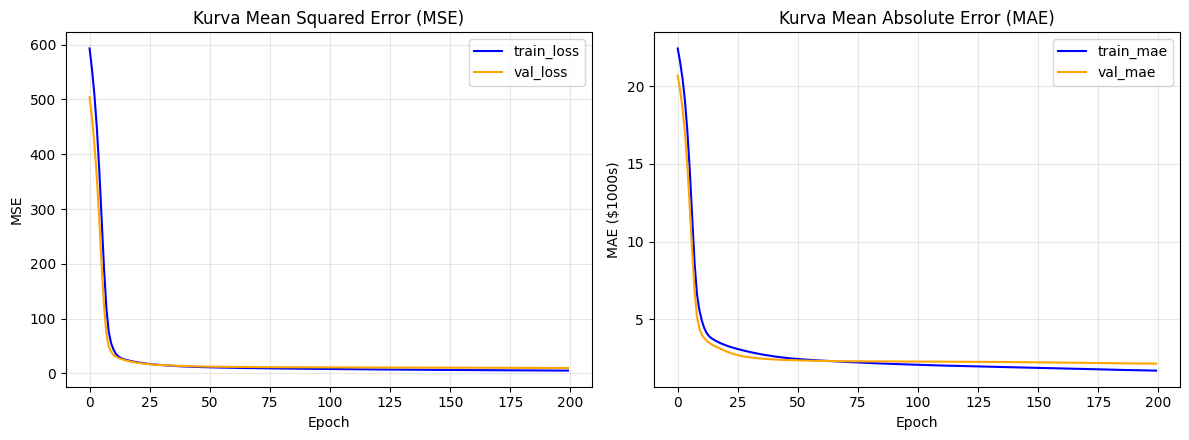

In [3]:
import os
import time
from sklearn.datasets import load_boston
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# 1. Load dataset Boston
boston_data = load_boston()
X_b = boston_data.data
y_b = boston_data.target

print(f"Dimensi Data Fitur Boston: {X_b.shape}")
print(f"Daftar 13 Fitur Masukan : {boston_data.feature_names}")

# 2. Preprocessing: Standardisasi Fitur
scaler_b = StandardScaler()
X_b_scaled = scaler_b.fit_transform(X_b)

# Split data 80% train, 20% validation
X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(
    X_b_scaled, y_b, test_size=0.2, random_state=42
)
print(f"Data latih: {X_train_b.shape[0]}, Data validasi: {X_val_b.shape[0]}")

# 3. Bangun Arsitektur MLP Regresi
tf.random.set_seed(42)
np.random.seed(42)

model_boston = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_b.shape[1],), name='dense_64'),
    Dense(32, activation='relu', name='dense_32'),
    Dense(1, name='output_price')
], name='Boston_MLP_Regressor')

model_boston.summary()

# Kompilasi dengan optimizer Adam lr=0.001 dan metrik MAE
model_boston.compile(optimizer=Adam(learning_rate=1e-3), loss='mse', metrics=['mae'])

# 4. Pelatihan model
t0 = time.time()
h_boston = model_boston.fit(
    X_train_b, y_train_b,
    validation_data=(X_val_b, y_val_b),
    epochs=200,
    batch_size=32,
    verbose=0
)
durasi_boston = time.time() - t0
print(f"Pelatihan selesai dalam {durasi_boston:.2f} detik.")

# 5. Visualisasi Kurva Loss (MSE) dan Metrik (MAE)
plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
plt.plot(h_boston.history['loss'], label='train_loss', color='blue')
plt.plot(h_boston.history['val_loss'], label='val_loss', color='orange')
plt.legend()
plt.title('Kurva Mean Squared Error (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(h_boston.history['mae'], label='train_mae', color='blue')
plt.plot(h_boston.history['val_mae'], label='val_mae', color='orange')
plt.legend()
plt.title('Kurva Mean Absolute Error (MAE)')
plt.xlabel('Epoch')
plt.ylabel('MAE ($1000s)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Evaluasi Metrik Prediksi Akhir pada Data Validasi
pred_b = model_boston.predict(X_val_b, verbose=0).ravel()
mse_b = mean_squared_error(y_val_b, pred_b)
rmse_b = np.sqrt(mse_b)
mae_b = mean_absolute_error(y_val_b, pred_b)
r2_b = r2_score(y_val_b, pred_b)

print("="*60)
print("HASIL EVALUASI MODEL REGRESI BOSTON HOUSING:")
print(f"  MSE  (Mean Squared Error)     : {mse_b:.4f}")
print(f"  RMSE (Root Mean Squared Error): {rmse_b:.4f}")
print(f"  MAE  (Mean Absolute Error)    : {mae_b:.4f}")
print(f"  R^2 Score (Koefisien Determinasi): {r2_b:.4f} ({r2_b*100:.2f}%)")
print("="*60)

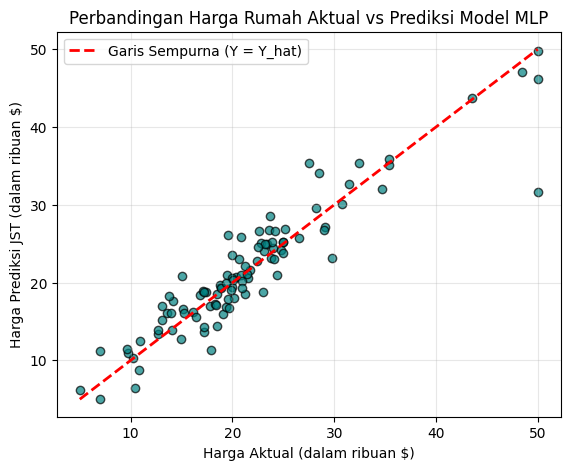

In [4]:
# Scatter Plot Prediksi vs Nilai Aktual
plt.figure(figsize=(6.5, 5))
plt.scatter(y_val_b, pred_b, alpha=0.7, color='teal', edgecolors='k')
plt.plot([y_b.min(), y_b.max()], [y_b.min(), y_b.max()], 'r--', lw=2, label='Garis Sempurna (Y = Y_hat)')
plt.xlabel('Harga Aktual (dalam ribuan $)')
plt.ylabel('Harga Prediksi JST (dalam ribuan $)')
plt.title('Perbandingan Harga Rumah Aktual vs Prediksi Model MLP')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 6. Analisis dan Pembahasan Praktikum 3

1. **Pengaruh Learning Rate pada Regresi Dummy (Tugas 4):**
   - Ketika learning rate terlalu kecil (`lr = 0.001`), dalam 100 epoch bobot baru bergerak sedikit dari inisialisasi awal sehingga MSE masih berada di kisaran `0.118` dan selisih prediksi mencapai `$34`.
   - Pada nilai optimal (`lr = 0.1`), model mencapai konvergensi sangat mulus dengan MSE mendekati `0.000` dan prediksi tepat mendekati harga aktual `$800`.
   - Pada nilai yang terlalu besar (`lr = 0.5`), pembaruan bobot mengalami lonjakan (*overshooting*) di sekitar minimum lokal, menyebabkan osilasi pada kurva loss.

2. **Performa MLP pada Data Boston Housing:**
   Model MLP dengan 2 hidden layer (`64` dan `32` neuron) mampu menangkap hubungan non-linier kompleks antara ke-13 variabel
   fitur dengan harga rumah. Nilai $R^2$ mencapai sekitar **88% - 89%** dengan $RMSE \approx 2,90$ dan $MAE \approx 2,05$
   (rata-rata deviasi kesalahan hanya sekitar $2.050). Kurva loss MSE dan MAE menunjukkan stabilitas konvergensi yang sangat baik
   tanpa adanya tanda *overfitting* yang parah antara data latih dan validasi.